<a href="https://colab.research.google.com/github/ibrahimhanifceker/Cubing_Project/blob/main/hafta-12/YZ50Hafta12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from transformers import GPT2LMHeadModel

In [ ]:
model_hf = GPT2LMHeadModel.from_pretrained("gpt2")
sd_hf = model_hf.state_dict()

for k, v in sd_hf.items():
    print(k, v.shape)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

transformer.wte.weight torch.Size([50257, 768])
transformer.wpe.weight torch.Size([1024, 768])
transformer.h.0.ln_1.weight torch.Size([768])
transformer.h.0.ln_1.bias torch.Size([768])
transformer.h.0.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.0.attn.c_attn.bias torch.Size([2304])
transformer.h.0.attn.c_proj.weight torch.Size([768, 768])
transformer.h.0.attn.c_proj.bias torch.Size([768])
transformer.h.0.ln_2.weight torch.Size([768])
transformer.h.0.ln_2.bias torch.Size([768])
transformer.h.0.mlp.c_fc.weight torch.Size([768, 3072])
transformer.h.0.mlp.c_fc.bias torch.Size([3072])
transformer.h.0.mlp.c_proj.weight torch.Size([3072, 768])
transformer.h.0.mlp.c_proj.bias torch.Size([768])
transformer.h.1.ln_1.weight torch.Size([768])
transformer.h.1.ln_1.bias torch.Size([768])
transformer.h.1.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.1.attn.c_attn.bias torch.Size([2304])
transformer.h.1.attn.c_proj.weight torch.Size([768, 768])
transformer.h.1.attn.c_proj.bias 

In [ ]:
tot_param = 0;
for k, v in sd_hf.items():
    tot_param += v.nelement()

print(f"{tot_param :.2e}")

1.63e+08


In [ ]:
from transformers import pipeline, set_seed
generator = pipeline('text-generation', model='gpt2')
set_seed(42)
generator("Hello, I am a langauge model,", max_length=30, num_return_sequences=5)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'generated_text': 'Hello, I am a langauge model, so I have to say that some people are going to be interested in the idea of creating a 3'},
 {'generated_text': 'Hello, I am a langauge model, I am a langauge model of myself.\n\nThe next question is, do you have'},
 {'generated_text': 'Hello, I am a langauge model, I am an avian model, and I am a model of a man. I think I am'},
 {'generated_text': "Hello, I am a langauge model, and it's not about me. On the contrary, it's about me. I was born in"},
 {'generated_text': 'Hello, I am a langauge model, not a scientist or even a journalist and I have no idea what this topic is about. This is'}]

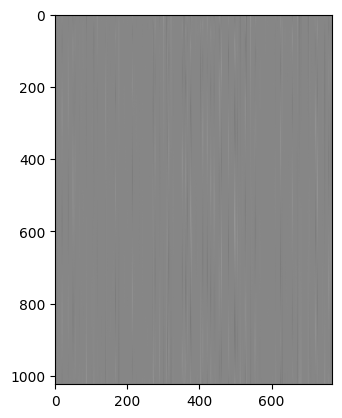

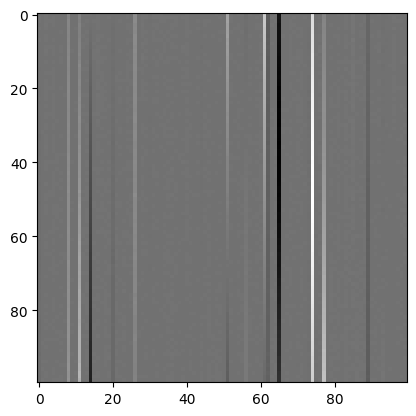

In [ ]:
import matplotlib.pyplot as plt

plt.figure(0)
plt.imshow(sd_hf["transformer.wpe.weight"][:, :], cmap="gray")
plt.figure(1);
plt.imshow(sd_hf["transformer.wpe.weight"][500:600, 300:400], cmap="gray")

In [ ]:
# Pozisyon embeddinglerinde bazi indekslerin her pozisyon icin aktif ya da deaktif oldugunu gorebiliriz.
# Ayrica, bazi embedding dimnesionlari pozisyonla birlikte artan ya da azalan degerlere sahip.

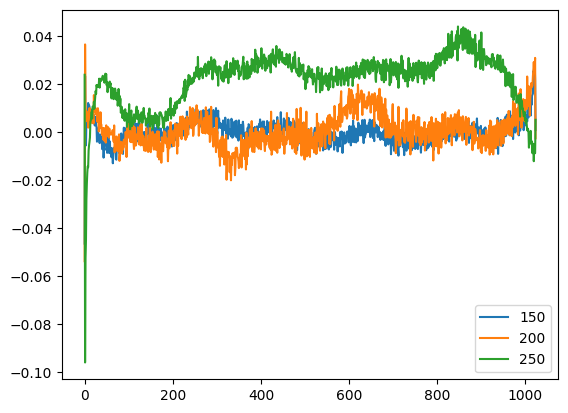

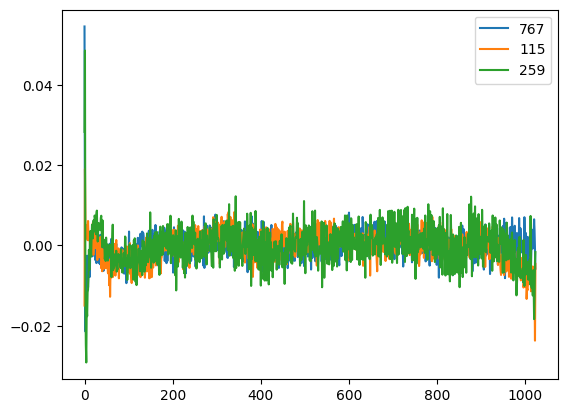

In [ ]:
plt.figure()
plt.plot(sd_hf["transformer.wpe.weight"][:, 150], label='150');
plt.plot(sd_hf["transformer.wpe.weight"][:, 200], label='200');
plt.plot(sd_hf["transformer.wpe.weight"][:, 250], label='250');
plt.legend();
plt.figure()
plt.plot(sd_hf["transformer.wpe.weight"][:, -1], label='767');
plt.plot(sd_hf["transformer.wpe.weight"][:, 115], label='115');
plt.plot(sd_hf["transformer.wpe.weight"][:, 259], label='259');
plt.legend();

In [ ]:
# Pozisyon embeddinglerinin ayni dimension icin genelde dalga gibi davrandigini goruyorum.

In [ ]:
from dataclasses import dataclass
import torch
import torch.nn as nn
from torch.nn import functional as F
import math

In [ ]:
class CasualSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.SCALE_INIT_NORM_LAYER = 1
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size).view(1, 1, config.block_size, config.block_size)))

    def forward(self, x):
        B, T, C = x.size()
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        att = (q @ k.transpose(-2, -1) * (1.0 / math.sqrt(k.size(-1))))
        att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        y = self.c_proj(y)
        return y


In [ ]:
class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate='tanh')
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.SCALE_INIT_NORM_LAYER = 1


    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x

In [ ]:
class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CasualSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

In [ ]:
@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12
    n_head : int = 12
    n_embd: int  = 768

In [ ]:
class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        self.transformer.wte.weight = self.lm_head.weight

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, 'SCALE_INIT_NORM_LAYER'):
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.size()
        assert T <= self.config.block_size
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        pos_emb = self.transformer.wpe(pos)
        tok_emb = self.transformer.wte(idx)
        x = tok_emb + pos_emb
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(B*T, -1), targets.view(-1))
        return logits, loss

    @classmethod
    def from_pretrained(cls, model_type):
        assert model_type in {'gpt2', 'gpt2-medium', 'gpt2-large', 'gpt2-xl'}
        from transformers import GPT2LMHeadModel
        print(f"loading weights from the model {model_type}")
        config_args = {
            'gpt2':         dict(n_layer=12, n_head=12, n_embd=768),
            'gpt2-medium':  dict(n_layer=12, n_head=12, n_embd=768),
            'gpt2-large':   dict(n_layer=12, n_head=12, n_embd=768),
            'gpt2-xl':      dict(n_layer=12, n_head=12, n_embd=768),
        }[model_type]
        config_args['vocab_size'] = 50257
        config_args['block_size'] = 1024
        config = GPTConfig(**config_args)
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)
        sd_hf = model_hf.state_dict()
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
            if any(k.endswith(w) for w in transposed):
                assert sd_hf[k].shape[::-1] == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k].t())
            else:
                assert sd_hf[k].shape == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k])
        return model

In [ ]:
model = GPT.from_pretrained('gpt2')

loading weights from the model gpt2


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [ ]:
tokens = torch.tensor([[1, 2, 3], [4, 5, 6]])
logits = model(tokens)[0].data
logits_hf = model_hf(tokens)
print(torch.stack((logits, logits_hf[0].data), dim=-1))
print(f"Does the loaded model give the same logits as the original model? {logits.allclose(logits_hf[0].data)}")

tensor([[[[-32.9010, -32.9011],
          [-31.2024, -31.2024],
          [-34.6622, -34.6622],
          ...,
          [-39.4867, -39.4867],
          [-39.8731, -39.8732],
          [-32.2387, -32.2387]],

         [[-55.5208, -55.5207],
          [-53.4285, -53.4285],
          [-56.4767, -56.4767],
          ...,
          [-68.1539, -68.1539],
          [-66.7709, -66.7708],
          [-58.6006, -58.6006]],

         [[-61.7969, -61.7969],
          [-60.5386, -60.5386],
          [-59.5503, -59.5503],
          ...,
          [-75.3206, -75.3206],
          [-72.7731, -72.7731],
          [-65.5706, -65.5706]]],


        [[[-34.2117, -34.2118],
          [-33.7478, -33.7479],
          [-36.0369, -36.0370],
          ...,
          [-41.5752, -41.5752],
          [-41.8641, -41.8642],
          [-33.8159, -33.8160]],

         [[-76.9006, -76.9006],
          [-78.5744, -78.5744],
          [-75.4780, -75.4781],
          ...,
          [-89.0610, -89.0610],
          [-87.8098

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("The current device used is " + device)

num_return_sequences = 5
max_length = 30

model = GPT.from_pretrained('gpt2')
model.eval()
model.to(device)

The current device used is cuda
loading weights from the model gpt2


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT(
  (transformer): ModuleDict(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (h): ModuleList(
      (0-11): 12 x Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): CasualSelfAttention(
          (c_attn): Linear(in_features=768, out_features=2304, bias=True)
          (c_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): MLP(
          (c_fc): Linear(in_features=768, out_features=3072, bias=True)
          (gelu): GELU(approximate='tanh')
          (c_proj): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [ ]:
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Would you like to learn something new? ")
print(len(tokens))
tokens = torch.tensor(tokens, dtype=torch.long)
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)
x = tokens.to(device)

9


In [ ]:
def generate_text():
    global x
    torch.manual_seed(42)
    torch.cuda.manual_seed(42)
    while x.size(1) < max_length:
        with torch.no_grad():
            logits = model(x)[0]
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
            idx = torch.multinomial(topk_probs, 1)
            xcol = torch.gather(topk_indices, -1, idx)
            x = torch.cat((x, xcol), dim=1)

In [ ]:
generate_text()

for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(decoded)

Would you like to learn something new?  If so, you can send me a review and I will let you know. If you don't
Would you like to learn something new?  The New York Times  doesn't seem thrilled to have the '90s as its annual feature
Would you like to learn something new? ________________________________________ For those of you who like to write some code you could also check out the documentation on GitHub
Would you like to learn something new?  The Best of the Best is at http://www.chicago-bios.com/ 
Would you like to learn something new?  Tell me about it at my Ask Me Anything
I don't expect to have to do the whole


In [ ]:
max_length = 30

tokens = enc.encode("Yeni bir şey öğrenmek ister misin? ")
print(len(tokens))
tokens = torch.tensor(tokens, dtype=torch.long)
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)
x = tokens.to(device)

generate_text()

for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(decoded)

18
Yeni bir şey öğrenmek ister misin? ğrí nüüy nemşenu
Yeni bir şey öğrenmek ister misin? тсе се рас /u
Yeni bir şey öğrenmek ister misin? ik: ĆisĿĿ ĵk
Yeni bir şey öğrenmek ister misin? ich inıyın, dıyaşı
Yeni bir şey öğrenmek ister misin? iz han zu gekud yemmü


In [ ]:
import os

if not os.path.isfile("input.txt"):
    !wget https://raw.githubusercontent.com/karpathy/char-rnn/refs/heads/master/data/tinyshakespeare/input.txt

with open('input.txt', 'r') as f:
    text = f.read()
text = text[:1000]

--2026-11-15 07:05:02--  https://raw.githubusercontent.com/karpathy/char-rnn/refs/heads/master/data/tinyshakespeare/input.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1115394 (1.1M) [text/plain]
Saving to: ‘input.txt’

input.txt           100%[===================>]   1.06M  --.-KB/s    in 0.03s   

2026-11-15 07:05:02 (36.5 MB/s) - ‘input.txt’ saved [1115394/1115394]



In [ ]:
tokens = enc.encode(text)
B, T = 4, 32
buffer = torch.tensor(tokens[:B*T + 1], device=device)
x = buffer[:-1].view(B, T)
y = buffer[1:].view(B, T)

In [ ]:
model = GPT(GPTConfig())
model.to(device)
logits, loss = model(x, y)
print(loss.item(), -math.log(1.0 / GPTConfig().vocab_size))

11.008783340454102 10.82490511970208


In [ ]:
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

epochs = 200
for epoch in range(epochs):
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    if epoch % 10 == 0:
        print(f"epoch: {epoch}, loss: {loss.item()}")

epoch: 0, loss: 11.008783340454102
epoch: 10, loss: 6.794583320617676
epoch: 20, loss: 3.894620895385742
epoch: 30, loss: 1.9155292510986328
epoch: 40, loss: 0.6221493482589722
epoch: 50, loss: 0.1252499222755432
epoch: 60, loss: 0.027119919657707214
epoch: 70, loss: 0.010912028141319752
epoch: 80, loss: 0.006306804250925779
epoch: 90, loss: 0.004464089870452881
epoch: 100, loss: 0.0035283835604786873
epoch: 110, loss: 0.0029831519350409508
epoch: 120, loss: 0.002616875572130084
epoch: 130, loss: 0.002342449501156807
epoch: 140, loss: 0.002124146092683077
epoch: 150, loss: 0.0019432395929470658
epoch: 160, loss: 0.0017895561177283525
epoch: 170, loss: 0.0016567915445193648
epoch: 180, loss: 0.001540702534839511
epoch: 190, loss: 0.0014383085072040558


Hafta Baslangici

In [ ]:
class DataLoaderLite:
    def __init__(self, B, T):
        super().__init__()
        self.B = B
        self.T = T

        with open('input.txt', 'r') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens)
        print(f"Number of tokens loaded is {len(self.tokens)}")
        self.current_position = 0

    def next_batch(self):
        B, T = self.B, self.T
        buf = self.tokens[self.current_position : self.current_position + B * T + 1]
        x = (buf[:-1]).view(B, T)
        y = (buf[1:]).view(B, T)
        self.current_position += B * T
        if self.current_position + (B * T + 1) > len(self.tokens):
            self.current_position = 0
        return x, y


In [ ]:
torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B=4, T=32)

model = GPT(GPTConfig())
model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

epochs = 50
for epoch in range(epochs):
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    if epoch % 10 == 0:
        print(f"epoch: {epoch}, loss: {loss.item()}")

Number of tokens loaded is 338025
epoch: 0, loss: 10.960028648376465
epoch: 10, loss: 8.380849838256836
epoch: 20, loss: 7.505931854248047
epoch: 30, loss: 6.990047454833984
epoch: 40, loss: 7.416410446166992


In [ ]:
# default casting
import time

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B=4, T=1024)

model = GPT(GPTConfig())
model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

epochs = 50
for epoch in range(epochs):
    time_i = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    torch.cuda.synchronize()
    time_f = time.time()
    delta_time = (time_f - time_i) * 1000
    tokens_per_sec = (train_loader.B * train_loader.T) / (time_f - time_i)
    print(f"epoch: {epoch}, loss: {loss.item()}, dt: {delta_time:.2f}ms, tok/sec: {tokens_per_sec:.2f}")

Number of tokens loaded is 338025
epoch: 0, loss: 10.928553581237793, dt: 1312.16ms, tok/sec: 3121.57
epoch: 1, loss: 9.525257110595703, dt: 1221.68ms, tok/sec: 3352.76
epoch: 2, loss: 8.986088752746582, dt: 1236.18ms, tok/sec: 3313.44
epoch: 3, loss: 8.6998929977417, dt: 1231.79ms, tok/sec: 3325.25
epoch: 4, loss: 8.393762588500977, dt: 1230.91ms, tok/sec: 3327.63
epoch: 5, loss: 8.02257251739502, dt: 1231.97ms, tok/sec: 3324.77
epoch: 6, loss: 7.910907745361328, dt: 1230.31ms, tok/sec: 3329.24
epoch: 7, loss: 7.710430145263672, dt: 1236.21ms, tok/sec: 3313.35
epoch: 8, loss: 7.629522323608398, dt: 1242.39ms, tok/sec: 3296.87
epoch: 9, loss: 7.342772006988525, dt: 1237.65ms, tok/sec: 3309.50
epoch: 10, loss: 7.358564376831055, dt: 1241.11ms, tok/sec: 3300.27
epoch: 11, loss: 7.35311222076416, dt: 1250.64ms, tok/sec: 3275.12
epoch: 12, loss: 7.409618854522705, dt: 1245.79ms, tok/sec: 3287.86
epoch: 13, loss: 7.307407379150391, dt: 1256.11ms, tok/sec: 3260.87
epoch: 14, loss: 6.91559886

In [ ]:
# TF32 casting
import time

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B=4, T=1024)

torch.set_float32_matmul_precision('high')

model = GPT(GPTConfig())
model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

epochs = 50
for epoch in range(epochs):
    time_i = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    torch.cuda.synchronize()
    time_f = time.time()
    delta_time = (time_f - time_i) * 1000
    tokens_per_sec = (train_loader.B * train_loader.T) / (time_f - time_i)
    print(f"epoch: {epoch}, loss: {loss.item()}, dt: {delta_time:.2f}ms, tok/sec: {tokens_per_sec:.2f}")

Number of tokens loaded is 338025
epoch: 0, loss: 10.928553581237793, dt: 1469.75ms, tok/sec: 2786.87
epoch: 1, loss: 9.525257110595703, dt: 1437.11ms, tok/sec: 2850.17
epoch: 2, loss: 8.986088752746582, dt: 1429.23ms, tok/sec: 2865.87
epoch: 3, loss: 8.6998929977417, dt: 1428.10ms, tok/sec: 2868.15
epoch: 4, loss: 8.393762588500977, dt: 1416.24ms, tok/sec: 2892.17
epoch: 5, loss: 8.02257251739502, dt: 1402.26ms, tok/sec: 2921.00
epoch: 6, loss: 7.910907745361328, dt: 1390.50ms, tok/sec: 2945.70
epoch: 7, loss: 7.710430145263672, dt: 1385.78ms, tok/sec: 2955.74
epoch: 8, loss: 7.629522323608398, dt: 1381.23ms, tok/sec: 2965.48
epoch: 9, loss: 7.342772006988525, dt: 1378.73ms, tok/sec: 2970.85
epoch: 10, loss: 7.358564376831055, dt: 1367.68ms, tok/sec: 2994.85
epoch: 11, loss: 7.35311222076416, dt: 1367.22ms, tok/sec: 2995.86
epoch: 12, loss: 7.409618854522705, dt: 1365.32ms, tok/sec: 3000.02
epoch: 13, loss: 7.307407379150391, dt: 1361.58ms, tok/sec: 3008.27
epoch: 14, loss: 6.91559886

In [ ]:
# bfloat16 casting
import time

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B=4, T=1024)

torch.set_float32_matmul_precision('high')

model = GPT(GPTConfig())
model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

epochs = 50
for epoch in range(epochs):
    time_i = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    with torch.autocast(device_type=device, dtype=torch.bfloat16):
        logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    torch.cuda.synchronize()
    time_f = time.time()
    delta_time = (time_f - time_i) * 1000
    tokens_per_sec = (train_loader.B * train_loader.T) / (time_f - time_i)
    print(f"epoch: {epoch}, loss: {loss.item()}, dt: {delta_time:.2f}ms, tok/sec: {tokens_per_sec:.2f}")

Number of tokens loaded is 338025
epoch: 0, loss: 10.9283447265625, dt: 1905.57ms, tok/sec: 2149.49
epoch: 1, loss: 9.525066375732422, dt: 1819.25ms, tok/sec: 2251.47
epoch: 2, loss: 8.986328125, dt: 1823.82ms, tok/sec: 2245.84
epoch: 3, loss: 8.700199127197266, dt: 1823.88ms, tok/sec: 2245.76
epoch: 4, loss: 8.395532608032227, dt: 1833.34ms, tok/sec: 2234.18
epoch: 5, loss: 8.023357391357422, dt: 1821.91ms, tok/sec: 2248.20
epoch: 6, loss: 7.910186767578125, dt: 1834.97ms, tok/sec: 2232.19
epoch: 7, loss: 7.710783004760742, dt: 1837.52ms, tok/sec: 2229.09
epoch: 8, loss: 7.62864875793457, dt: 1837.59ms, tok/sec: 2229.00
epoch: 9, loss: 7.344333648681641, dt: 1838.73ms, tok/sec: 2227.63
epoch: 10, loss: 7.35997200012207, dt: 1838.02ms, tok/sec: 2228.49
epoch: 11, loss: 7.353946685791016, dt: 1847.33ms, tok/sec: 2217.26
epoch: 12, loss: 7.409086227416992, dt: 1837.24ms, tok/sec: 2229.43
epoch: 13, loss: 7.308393478393555, dt: 1838.34ms, tok/sec: 2228.09
epoch: 14, loss: 6.91707038879394

In [ ]:
class CasualSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.SCALE_INIT_NORM_LAYER = 1
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size).view(1, 1, config.block_size, config.block_size)))

    def forward(self, x):
        B, T, C = x.size()
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        # att = (q @ k.transpose(-2, -1) * (1.0 / math.sqrt(k.size(-1))))
        # att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float('-inf'))
        # att = F.softmax(att, dim=-1)
        # y = att @ v
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        y = self.c_proj(y)
        return y


In [ ]:
class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate='tanh')
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.SCALE_INIT_NORM_LAYER = 1


    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x

In [ ]:
class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CasualSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

In [ ]:
class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        self.transformer.wte.weight = self.lm_head.weight

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, 'SCALE_INIT_NORM_LAYER'):
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.size()
        assert T <= self.config.block_size
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        pos_emb = self.transformer.wpe(pos)
        tok_emb = self.transformer.wte(idx)
        x = tok_emb + pos_emb
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(B*T, -1), targets.view(-1))
        return logits, loss

    @classmethod
    def from_pretrained(cls, model_type):
        assert model_type in {'gpt2', 'gpt2-medium', 'gpt2-large', 'gpt2-xl'}
        from transformers import GPT2LMHeadModel
        print(f"loading weights from the model {model_type}")
        config_args = {
            'gpt2':         dict(n_layer=12, n_head=12, n_embd=768),
            'gpt2-medium':  dict(n_layer=12, n_head=12, n_embd=768),
            'gpt2-large':   dict(n_layer=12, n_head=12, n_embd=768),
            'gpt2-xl':      dict(n_layer=12, n_head=12, n_embd=768),
        }[model_type]
        config_args['vocab_size'] = 50257
        config_args['block_size'] = 1024
        config = GPTConfig(**config_args)
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)
        sd_hf = model_hf.state_dict()
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
            if any(k.endswith(w) for w in transposed):
                assert sd_hf[k].shape[::-1] == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k].t())
            else:
                assert sd_hf[k].shape == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k])
        return model

In [ ]:
# TF32 casting with flashattention
import time

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B=4, T=1024)

torch.set_float32_matmul_precision('highest')

model = GPT(GPTConfig())
model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

epochs = 50
for epoch in range(epochs):
    time_i = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    torch.cuda.synchronize()
    time_f = time.time()
    delta_time = (time_f - time_i) * 1000
    tokens_per_sec = (train_loader.B * train_loader.T) / (time_f - time_i)
    print(f"epoch: {epoch}, loss: {loss.item()}, dt: {delta_time:.2f}ms, tok/sec: {tokens_per_sec:.2f}")

Number of tokens loaded is 338025
epoch: 0, loss: 10.928553581237793, dt: 1204.76ms, tok/sec: 3399.83
epoch: 1, loss: 9.525256156921387, dt: 1147.47ms, tok/sec: 3569.61
epoch: 2, loss: 8.986088752746582, dt: 1144.60ms, tok/sec: 3578.53
epoch: 3, loss: 8.6998929977417, dt: 1153.34ms, tok/sec: 3551.44
epoch: 4, loss: 8.393763542175293, dt: 1155.04ms, tok/sec: 3546.21
epoch: 5, loss: 8.022571563720703, dt: 1150.79ms, tok/sec: 3559.29
epoch: 6, loss: 7.910907745361328, dt: 1150.94ms, tok/sec: 3558.84
epoch: 7, loss: 7.710430145263672, dt: 1151.07ms, tok/sec: 3558.43
epoch: 8, loss: 7.629522323608398, dt: 1156.20ms, tok/sec: 3542.65
epoch: 9, loss: 7.342772006988525, dt: 1152.21ms, tok/sec: 3554.91
epoch: 10, loss: 7.3585638999938965, dt: 1151.58ms, tok/sec: 3556.85
epoch: 11, loss: 7.35311222076416, dt: 1155.20ms, tok/sec: 3545.72
epoch: 12, loss: 7.409618854522705, dt: 1154.90ms, tok/sec: 3546.63
epoch: 13, loss: 7.307406425476074, dt: 1161.14ms, tok/sec: 3527.56
epoch: 14, loss: 6.915597

In [ ]:
# TF32 casting with flashattention and rounded vocab_size
import time

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B=4, T=1024)

torch.set_float32_matmul_precision('highest')

model = GPT(GPTConfig(vocab_size=50304))
model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

epochs = 50
for epoch in range(epochs):
    time_i = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    torch.cuda.synchronize()
    time_f = time.time()
    delta_time = (time_f - time_i) * 1000
    tokens_per_sec = (train_loader.B * train_loader.T) / (time_f - time_i)
    print(f"epoch: {epoch}, loss: {loss.item()}, dt: {delta_time:.2f}ms, tok/sec: {tokens_per_sec:.2f}")

Number of tokens loaded is 338025
epoch: 0, loss: 10.928756713867188, dt: 1201.97ms, tok/sec: 3407.75
epoch: 1, loss: 9.511163711547852, dt: 1141.81ms, tok/sec: 3587.29
epoch: 2, loss: 9.022726058959961, dt: 1140.26ms, tok/sec: 3592.17
epoch: 3, loss: 8.803125381469727, dt: 1144.66ms, tok/sec: 3578.36
epoch: 4, loss: 8.404757499694824, dt: 1134.95ms, tok/sec: 3608.96
epoch: 5, loss: 8.018508911132812, dt: 1133.39ms, tok/sec: 3613.94
epoch: 6, loss: 7.959440231323242, dt: 1133.55ms, tok/sec: 3613.44
epoch: 7, loss: 7.715027332305908, dt: 1144.08ms, tok/sec: 3580.18
epoch: 8, loss: 7.64244270324707, dt: 1142.54ms, tok/sec: 3584.99
epoch: 9, loss: 7.386630535125732, dt: 1140.21ms, tok/sec: 3592.31
epoch: 10, loss: 7.417726516723633, dt: 1142.12ms, tok/sec: 3586.32
epoch: 11, loss: 7.389195919036865, dt: 1143.36ms, tok/sec: 3582.41
epoch: 12, loss: 7.463356018066406, dt: 1146.12ms, tok/sec: 3573.79
epoch: 13, loss: 7.392244338989258, dt: 1139.33ms, tok/sec: 3595.10
epoch: 14, loss: 7.03627



*   Default version: 1150-1200ms
*   TF32 casting: 1200-1250ms
*   bfloat16 casting: 1650-1700ms
*   TF32 with flashattention: 1050ms
*   TF32 with flashattention and rounded vocab_size: 1045ms



In [ ]:
import time

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B=4, T=1024)

torch.set_float32_matmul_precision('highest')

model = GPT(GPTConfig(vocab_size=50304))
model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, betas=(0.9, 0.95), eps=1e-8)

epochs = 50
for epoch in range(epochs):
    time_i = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    torch.cuda.synchronize()
    time_f = time.time()
    delta_time = (time_f - time_i) * 1000
    tokens_per_sec = (train_loader.B * train_loader.T) / (time_f - time_i)
    print(f"epoch: {epoch}, loss: {loss.item():.6f}, norm: {norm:.4f}, dt: {delta_time:.2f}ms, tok/sec: {tokens_per_sec:.2f}")

Number of tokens loaded is 338025
epoch: 0, loss: 10.928757, norm: 30.4259, dt: 1215.19ms, tok/sec: 3370.66
epoch: 1, loss: 9.511612, norm: 6.1820, dt: 1146.36ms, tok/sec: 3573.06
epoch: 2, loss: 9.002340, norm: 2.3709, dt: 1143.89ms, tok/sec: 3580.75
epoch: 3, loss: 8.802099, norm: 4.1313, dt: 1141.52ms, tok/sec: 3588.19
epoch: 4, loss: 8.388184, norm: 2.4516, dt: 1152.92ms, tok/sec: 3552.73
epoch: 5, loss: 7.979677, norm: 2.5404, dt: 1139.53ms, tok/sec: 3594.45
epoch: 6, loss: 7.888886, norm: 2.2774, dt: 1144.72ms, tok/sec: 3578.16
epoch: 7, loss: 7.658165, norm: 1.8512, dt: 1152.05ms, tok/sec: 3555.42
epoch: 8, loss: 7.560283, norm: 1.6844, dt: 1152.69ms, tok/sec: 3553.44
epoch: 9, loss: 7.276411, norm: 1.5502, dt: 1154.03ms, tok/sec: 3549.31
epoch: 10, loss: 7.299589, norm: 1.6927, dt: 1153.91ms, tok/sec: 3549.68
epoch: 11, loss: 7.220587, norm: 1.4248, dt: 1149.65ms, tok/sec: 3562.81
epoch: 12, loss: 7.266457, norm: 2.1506, dt: 1153.71ms, tok/sec: 3550.27
epoch: 13, loss: 7.165931

In [ ]:
max_lr = 6e-4
min_lr = max_lr * 0.1
warmup_steps = 10
max_steps = 50

In [ ]:
def get_lr(it):
    if it < warmup_steps:
        return max_lr * (it+1) / warmup_steps
    if it > max_steps:
        return min_lr
    decay_ratio = (it - warmup_steps) / (max_steps - warmup_steps)
    assert 0 <= decay_ratio <= 1
    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio))
    return min_lr + coeff * (max_lr - min_lr)

In [ ]:
import time

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B=4, T=1024)

torch.set_float32_matmul_precision('highest')

model = GPT(GPTConfig(vocab_size=50304))
model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, betas=(0.9, 0.95), eps=1e-8)

epochs = max_steps
for epoch in range(epochs):
    time_i = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    lr = get_lr(epoch)
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr
    optimizer.step()
    torch.cuda.synchronize()
    time_f = time.time()
    delta_time = (time_f - time_i) * 1000
    tokens_per_sec = (train_loader.B * train_loader.T) / (time_f - time_i)
    print(f"epoch: {epoch}, loss: {loss.item():.6f}, lr: {lr:.4e}, norm: {norm:.4f}, dt: {delta_time:.2f}ms, tok/sec: {tokens_per_sec:.2f}")

Number of tokens loaded is 338025
epoch: 0, loss: 10.928757, lr: 6.0000e-05, norm: 30.4259, dt: 1181.02ms, tok/sec: 3468.20
epoch: 1, loss: 9.615820, lr: 1.2000e-04, norm: 10.5642, dt: 1145.25ms, tok/sec: 3576.51
epoch: 2, loss: 9.303376, lr: 1.8000e-04, norm: 8.0511, dt: 1153.66ms, tok/sec: 3550.45
epoch: 3, loss: 9.684580, lr: 2.4000e-04, norm: 6.8213, dt: 1148.92ms, tok/sec: 3565.10
epoch: 4, loss: 9.003183, lr: 3.0000e-04, norm: 4.5167, dt: 1153.08ms, tok/sec: 3552.21
epoch: 5, loss: 8.377983, lr: 3.6000e-04, norm: 4.0629, dt: 1144.48ms, tok/sec: 3578.93
epoch: 6, loss: 8.216591, lr: 4.2000e-04, norm: 2.6405, dt: 1145.67ms, tok/sec: 3575.19
epoch: 7, loss: 7.931314, lr: 4.8000e-04, norm: 2.7572, dt: 1141.93ms, tok/sec: 3586.90
epoch: 8, loss: 7.716256, lr: 5.4000e-04, norm: 1.9215, dt: 1145.22ms, tok/sec: 3576.60
epoch: 9, loss: 7.297479, lr: 6.0000e-04, norm: 2.1374, dt: 1150.32ms, tok/sec: 3560.74
epoch: 10, loss: 7.158658, lr: 6.0000e-04, norm: 1.6670, dt: 1143.61ms, tok/sec: 35

In [ ]:
import inspect

class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        self.transformer.wte.weight = self.lm_head.weight

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, 'SCALE_INIT_NORM_LAYER'):
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.size()
        assert T <= self.config.block_size
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        pos_emb = self.transformer.wpe(pos)
        tok_emb = self.transformer.wte(idx)
        x = tok_emb + pos_emb
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(B*T, -1), targets.view(-1))
        return logits, loss

    @classmethod
    def from_pretrained(cls, model_type):
        assert model_type in {'gpt2', 'gpt2-medium', 'gpt2-large', 'gpt2-xl'}
        from transformers import GPT2LMHeadModel
        print(f"loading weights from the model {model_type}")
        config_args = {
            'gpt2':         dict(n_layer=12, n_head=12, n_embd=768),
            'gpt2-medium':  dict(n_layer=12, n_head=12, n_embd=768),
            'gpt2-large':   dict(n_layer=12, n_head=12, n_embd=768),
            'gpt2-xl':      dict(n_layer=12, n_head=12, n_embd=768),
        }[model_type]
        config_args['vocab_size'] = 50257
        config_args['block_size'] = 1024
        config = GPTConfig(**config_args)
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)
        sd_hf = model_hf.state_dict()
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
            if any(k.endswith(w) for w in transposed):
                assert sd_hf[k].shape[::-1] == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k].t())
            else:
                assert sd_hf[k].shape == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k])
        return model

    def configure_optimizers(self, weight_decay, learning_rate, device):
        param_dict = {name: param for name, param in self.named_parameters()}
        param_dict = {name: param for name, param in param_dict.items() if param.requires_grad}

        decay_params = [param for name, param in param_dict.items() if param.dim() >= 2]
        nodecay_params = [param for name, param in param_dict.items() if param.dim() < 2]

        optim_groups = [
            {"params": decay_params, "weight_decay": weight_decay},
            {"params": nodecay_params, "weight_decay": 0.0}
        ]

        fused_available = "fused" in inspect.signature(torch.optim.AdamW).parameters
        use_fused = fused_available and "cuda" in device
        optimizer = torch.optim.AdamW(optim_groups, lr=learning_rate, betas=(0.9, 0.95), eps=1e-8, fused=use_fused)
        return optimizer

In [ ]:
import time

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B=4, T=1024)

torch.set_float32_matmul_precision('highest')

model = GPT(GPTConfig(vocab_size=50304))
model.to(device)

optimizer = model.configure_optimizers(weight_decay=0.1, learning_rate=6e-4, device=device)

epochs = max_steps
for epoch in range(epochs):
    time_i = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    lr = get_lr(epoch)
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr
    optimizer.step()
    torch.cuda.synchronize()
    time_f = time.time()
    delta_time = (time_f - time_i) * 1000
    tokens_per_sec = (train_loader.B * train_loader.T) / (time_f - time_i)
    print(f"epoch: {epoch}, loss: {loss.item():.6f}, lr: {lr:.4e}, norm: {norm:.4f}, dt: {delta_time:.2f}ms, tok/sec: {tokens_per_sec:.2f}")

Number of tokens loaded is 338025
epoch: 0, loss: 10.928757, lr: 6.0000e-05, norm: 30.4259, dt: 1168.63ms, tok/sec: 3504.96
epoch: 1, loss: 9.615824, lr: 1.2000e-04, norm: 10.5642, dt: 1129.13ms, tok/sec: 3627.56
epoch: 2, loss: 9.303373, lr: 1.8000e-04, norm: 8.0503, dt: 1127.42ms, tok/sec: 3633.08
epoch: 3, loss: 9.684586, lr: 2.4000e-04, norm: 6.8213, dt: 1118.63ms, tok/sec: 3661.61
epoch: 4, loss: 9.003213, lr: 3.0000e-04, norm: 4.5167, dt: 1116.63ms, tok/sec: 3668.17
epoch: 5, loss: 8.378071, lr: 3.6000e-04, norm: 4.0632, dt: 1122.72ms, tok/sec: 3648.27
epoch: 6, loss: 8.216648, lr: 4.2000e-04, norm: 2.6391, dt: 1121.36ms, tok/sec: 3652.72
epoch: 7, loss: 7.931409, lr: 4.8000e-04, norm: 2.7558, dt: 1117.21ms, tok/sec: 3666.28
epoch: 8, loss: 7.716386, lr: 5.4000e-04, norm: 1.9219, dt: 1123.19ms, tok/sec: 3646.74
epoch: 9, loss: 7.297657, lr: 6.0000e-04, norm: 2.1379, dt: 1125.45ms, tok/sec: 3639.43
epoch: 10, loss: 7.158813, lr: 6.0000e-04, norm: 1.6671, dt: 1129.41ms, tok/sec: 36

In [ ]:
total_batch = 524288
B = 16
T = 1024
assert total_batch % (B * T) == 0, "total batch size must be divisible by the num of tokens in the micro batch (B * T)"
grad_steps = total_batch // (B * T)

In [ ]:
import time

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B=4, T=1024)

torch.set_float32_matmul_precision('highest')

model = GPT(GPTConfig(vocab_size=50304))
model.to(device)

optimizer = model.configure_optimizers(weight_decay=0.1, learning_rate=6e-4, device=device)

epochs = 5
for epoch in range(epochs):
    time_i = time.time()
    optimizer.zero_grad()
    loss_sum = 0.0
    for micro_step in range(grad_steps):
        x, y = train_loader.next_batch()
        x, y = x.to(device), y.to(device)
        logits, loss = model(x, y)
        loss = loss / grad_steps
        loss_sum += loss.detach()
        loss.backward()
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    lr = get_lr(epoch)
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr
    optimizer.step()
    torch.cuda.synchronize()
    time_f = time.time()
    delta_time = (time_f - time_i) * 1000
    tokens_per_sec = (train_loader.B * train_loader.T) / (time_f - time_i)
    print(f"epoch: {epoch}, loss: {loss_sum.item():.6f}, lr: {lr:.4e}, norm: {norm:.4f}, dt: {delta_time:.2f}ms, tok/sec: {tokens_per_sec:.2f}")

Number of tokens loaded is 338025
epoch: 0, loss: 10.938127, lr: 6.0000e-05, norm: 27.1169, dt: 35988.40ms, tok/sec: 113.81
epoch: 1, loss: 9.668528, lr: 1.2000e-04, norm: 9.3897, dt: 35936.25ms, tok/sec: 113.98
epoch: 2, loss: 9.157449, lr: 1.8000e-04, norm: 4.2672, dt: 35583.40ms, tok/sec: 115.11
epoch: 3, loss: 9.700597, lr: 2.4000e-04, norm: 7.4596, dt: 35614.22ms, tok/sec: 115.01
epoch: 4, loss: 9.031175, lr: 3.0000e-04, norm: 4.2270, dt: 35686.28ms, tok/sec: 114.78


In [ ]:
import os
import multiprocessing as mp
import numpy as np
import tiktoken
from datasets import load_dataset
from tqdm import tqdm

In [ ]:
local_dir = "edu_fineweb10B"
remote_name = "sample-10BT"
shard_size = int(1e8)

from pathlib import Path

try:
    base_dir = os.path.dirname(os.path.abspath(__file__))
except NameError:
    base_dir = Path.cwd()

DATA_CACHE_DIR = os.path.join(base_dir, local_dir)
os.makedirs(DATA_CACHE_DIR, exist_ok=True)

fw = load_dataset("HuggingFaceFW/fineweb-edu", name=remote_name, split="train")

Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

Generating train split:   0%|          | 0/9672101 [00:00<?, ? examples/s]

In [ ]:
enc = tiktoken.get_encoding("gpt2")
eot = enc._special_tokens['<|endoftext|>']
def tokenize(doc):
    tokens = [eot]
    tokens.extend(enc.encode_ordinary(doc["text"]))
    tokens_np = np.array(tokens)
    assert (0 <= tokens_np).all() and (tokens_np < 2**16).all()
    tokens_np_uint16 = tokens_np.astype(np.uint16)
    return tokens_np_uint16

def write_datafile(filename, tokens_np):
    np.save(filename, tokens_np)

In [ ]:
nprocs = max(1, os.cpu_count()//2)
with mp.Pool(nprocs) as pool:
    shard_index = 0
    all_tokens_np = np.empty((shard_size,), dtype=np.uint16)
    token_count = 0
    progress_bar = None
    for tokens in pool.imap(tokenize, fw, chunksize=16):
        if token_count + len(tokens) < shard_size:
            all_tokens_np[token_count:token_count+len(tokens)] = tokens
            token_count += len(tokens)
            if progress_bar is None:
                progress_bar = tqdm(total=shard_size, unit="tokens", desc=f"Shard {shard_index}")
            progress_bar.update(len(tokens))
        else:
            split = "val" if shard_index == 0 else "train"
            filename = os.path.join(DATA_CACHE_DIR, f"edufineweb_{split}_{shard_index:06d}")

            remainder = shard_size - token_count
            progress_bar.update(remainder)
            all_tokens_np[token_count:token_count+remainder] = tokens[:remainder]
            write_datafile(filename, all_tokens_np)
            shard_index += 1
            progress_bar = None

            all_tokens_np[0:len(tokens)-remainder] = tokens[remainder:]
            token_count = len(tokens)-remainder

    if token_count != 0:
        split = "val" if shard_index == 0 else "train"
        filename = os.path.join(DATA_CACHE_DIR, f"edufineweb_{split}_{shard_index:06d}")
        write_datafile(filename, all_tokens_np[:token_count])